In [1]:
import random

import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from imblearn.over_sampling import SMOTE

import optuna
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (f1_score, precision_score, recall_score, 
                             roc_auc_score, confusion_matrix, 
                             ConfusionMatrixDisplay)

import shap

In [2]:
# Reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# Telco Customer Churn: Exploratory Analysis and Prediction

## Business problem
A telecom company is losing customers (*churn*). Acquiring a new customer usually costs more than keeping an existing one, so the company wants to identify customers who are likely to leave and understand why, in order to target retention efforts effectively.

## Questions this notebook tries to answer
1. **How big is the problem?** What percentage of customers churn?
2. **Who churns?** Which customer groups (contract type, tenure, services, payment method) have the highest churn rate?
3. **Does money matter?** Do customers who churn pay more per month than those who stay?
4. **Are the differences real?** Which of the patterns I see are statistically meaningful and not just random noise?
5. **Can we predict it?** Can a machine learning model identify customers at risk of churning, and how well?
6. **What should the company do?** Which practical recommendations follow from the findings?

In [3]:
df = pd.read_csv("/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)

(7043, 21)


In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Dataset
- **Source:** Telco Customer Churn (IBM sample data, published on Kaggle by BlastChar)
- **Size:** 7,043 customers, 21 columns
- **Target variable:** Churn (Yes / No)
- **Features:** customer demographics, subscribed services, account information (contract, payment method, charges) and `tenure` (months as a customer)

## Approach
1. Data understanding and cleaning
2. SQL analysis of business questions
3. Exploratory Data Analysis (EDA) and visualization
4. Feature engineering
5. Modeling and validation
6. Interpretation and recommendations

> **How to read this notebook:** at each step I explain the decision I made, the alternatives I considered and why I chose one over the others.

## 1. Data overview

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
df.nunique()

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

The dataset contains 7,043 customers and 21 columns. Key observations:

- `customerID` is a unique identifier with no predictive value and will be dropped.
- Most columns are categorical (binary or with 2-4 categories). `tenure` and
  `MonthlyCharges` are continuous numeric. `TotalCharges` was read as `object`
  instead of `float64`, indicating hidden blank strings that require cleaning.
- The target variable `Churn` is binary (Yes/No).

Data quality issues identified and addressed in the next section.

In [8]:
# Exact unique values for columns with 2-4 unique values
cols = [c for c in df.columns if df[c].nunique() <= 4 and c != "customerID"]
for col in cols:
    print(df[col].value_counts(),'\n')

gender
Male      3555
Female    3488
Name: count, dtype: int64 

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64 

Partner
No     3641
Yes    3402
Name: count, dtype: int64 

Dependents
No     4933
Yes    2110
Name: count, dtype: int64 

PhoneService
Yes    6361
No      682
Name: count, dtype: int64 

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64 

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64 

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64 

OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64 

DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64 

TechSupport
No                     3473
Yes                    2044
No internet ser

In [9]:
# Count blank strings in TotalCharges
blank_total_charges = (df["TotalCharges"].str.strip() == "").sum()
print(f"Blank TotalCharges values: {blank_total_charges}")

Blank TotalCharges values: 11


In [10]:
# Rows where TotalCharges is blank
mask = df["TotalCharges"].str.strip() == ""
df[mask][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [11]:
# How many customers have tenure = 0?
print(df[df["tenure"] == 0].shape[0])

11


`TotalCharges` contained 11 blank strings, all corresponding to customers
with `tenure = 0` (new customers not yet billed). These were replaced with 0
and the column was converted to `float64`.

In [12]:
# Replace blank strings with 0 and convert TotalCharges to float64
df["TotalCharges"] = df["TotalCharges"].str.strip().replace("", "0")
df["TotalCharges"] = df["TotalCharges"].astype(float)

# Verify the fix
print(df["TotalCharges"].dtype)
print((df["TotalCharges"] == 0).sum())

float64
11


In [13]:
# Check for duplicate rows
print(f"Duplicate rows: {df.duplicated().sum()}")

Duplicate rows: 0


In [14]:
# Drop customerID - pure identifier with no predictive value
df = df.drop(columns=["customerID"])
print(f"Columns after drop: {df.shape[1]}")

Columns after drop: 20


## 2. Exploratory Data Analysis (EDA)

The goal of this section is to understand the data visually and statistically.
We start with the target variable, then look at each feature individually,
and finally examine how each feature relates to Churn.

In [15]:
# Class balance of the target variable
churn_counts = df["Churn"].value_counts()
churn_pct = df["Churn"].value_counts(normalize=True) * 100

print(churn_counts)
print()
print(churn_pct.round(1))

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


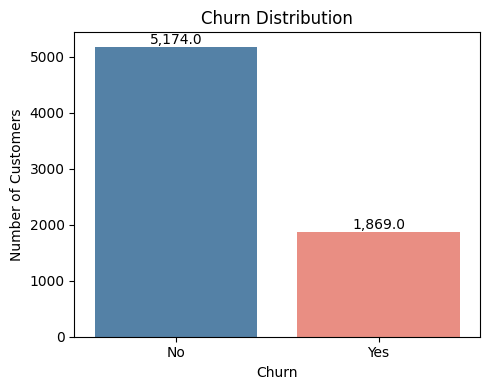

In [16]:
# Visualize class balance
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="Churn", hue="Churn", palette={"No": "steelblue", "Yes": "salmon"}, legend=False, ax=ax)
ax.set_title("Churn Distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of Customers")
for p in ax.patches:
    ax.annotate(f"{p.get_height():,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()

The dataset is imbalanced: 73.5% No / 26.5% Yes. Accuracy alone would be
misleading as a metric - F1, Precision, Recall and ROC-AUC will be used instead.

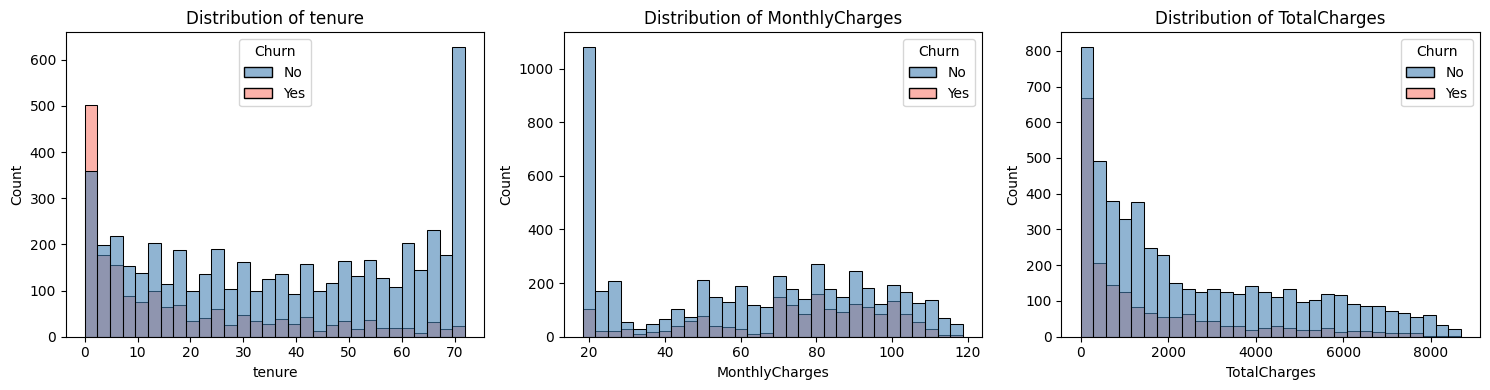

In [17]:
# Distribution of numeric features
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

for ax, col in zip(axes, numeric_cols):
    sns.histplot(data=df, x=col, hue="Churn", bins=30, 
                 palette={"No": "steelblue", "Yes": "salmon"},
                 ax=ax, alpha=0.6)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

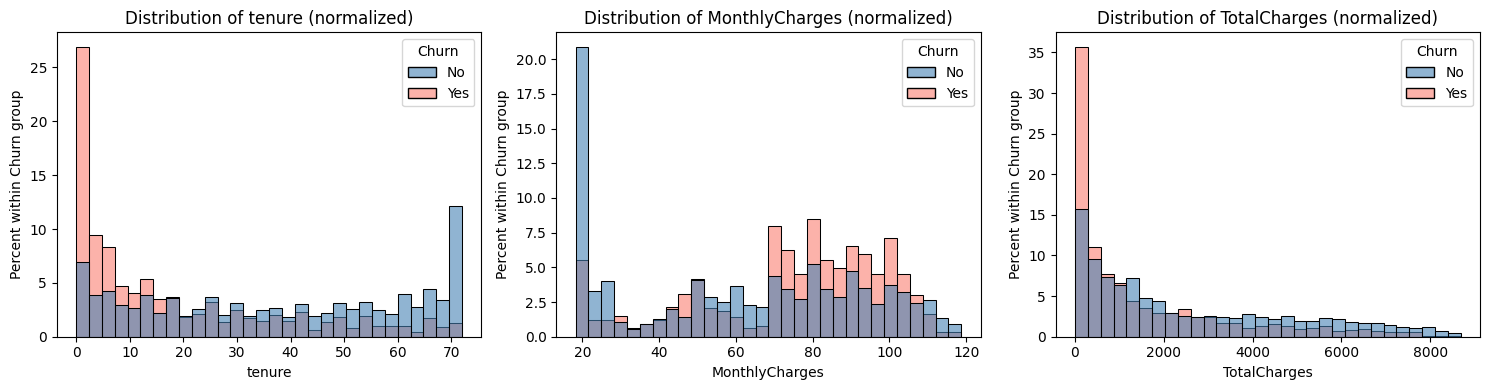

In [18]:
# Distribution of numeric features - normalized by Churn
# This shows the proportion of churners at each value range,
# removing the effect of class imbalance
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, numeric_cols):
    sns.histplot(data=df, x=col, hue="Churn", bins=30,
                 palette={"No": "steelblue", "Yes": "salmon"},
                 ax=ax, alpha=0.6, stat="percent", common_norm=False)
    ax.set_title(f"Distribution of {col} (normalized)")
    ax.set_xlabel(col)
    ax.set_ylabel("Percent within Churn group")

plt.tight_layout()
plt.show()

Churn rate decreases steadily with tenure - newer customers are significantly
more likely to leave. Higher MonthlyCharges are associated with higher churn.
TotalCharges is strongly correlated with both tenure and MonthlyCharges
(mathematically, TotalCharges ≈ tenure x MonthlyCharges), suggesting
multicollinearity. It will be dropped in the feature engineering step.

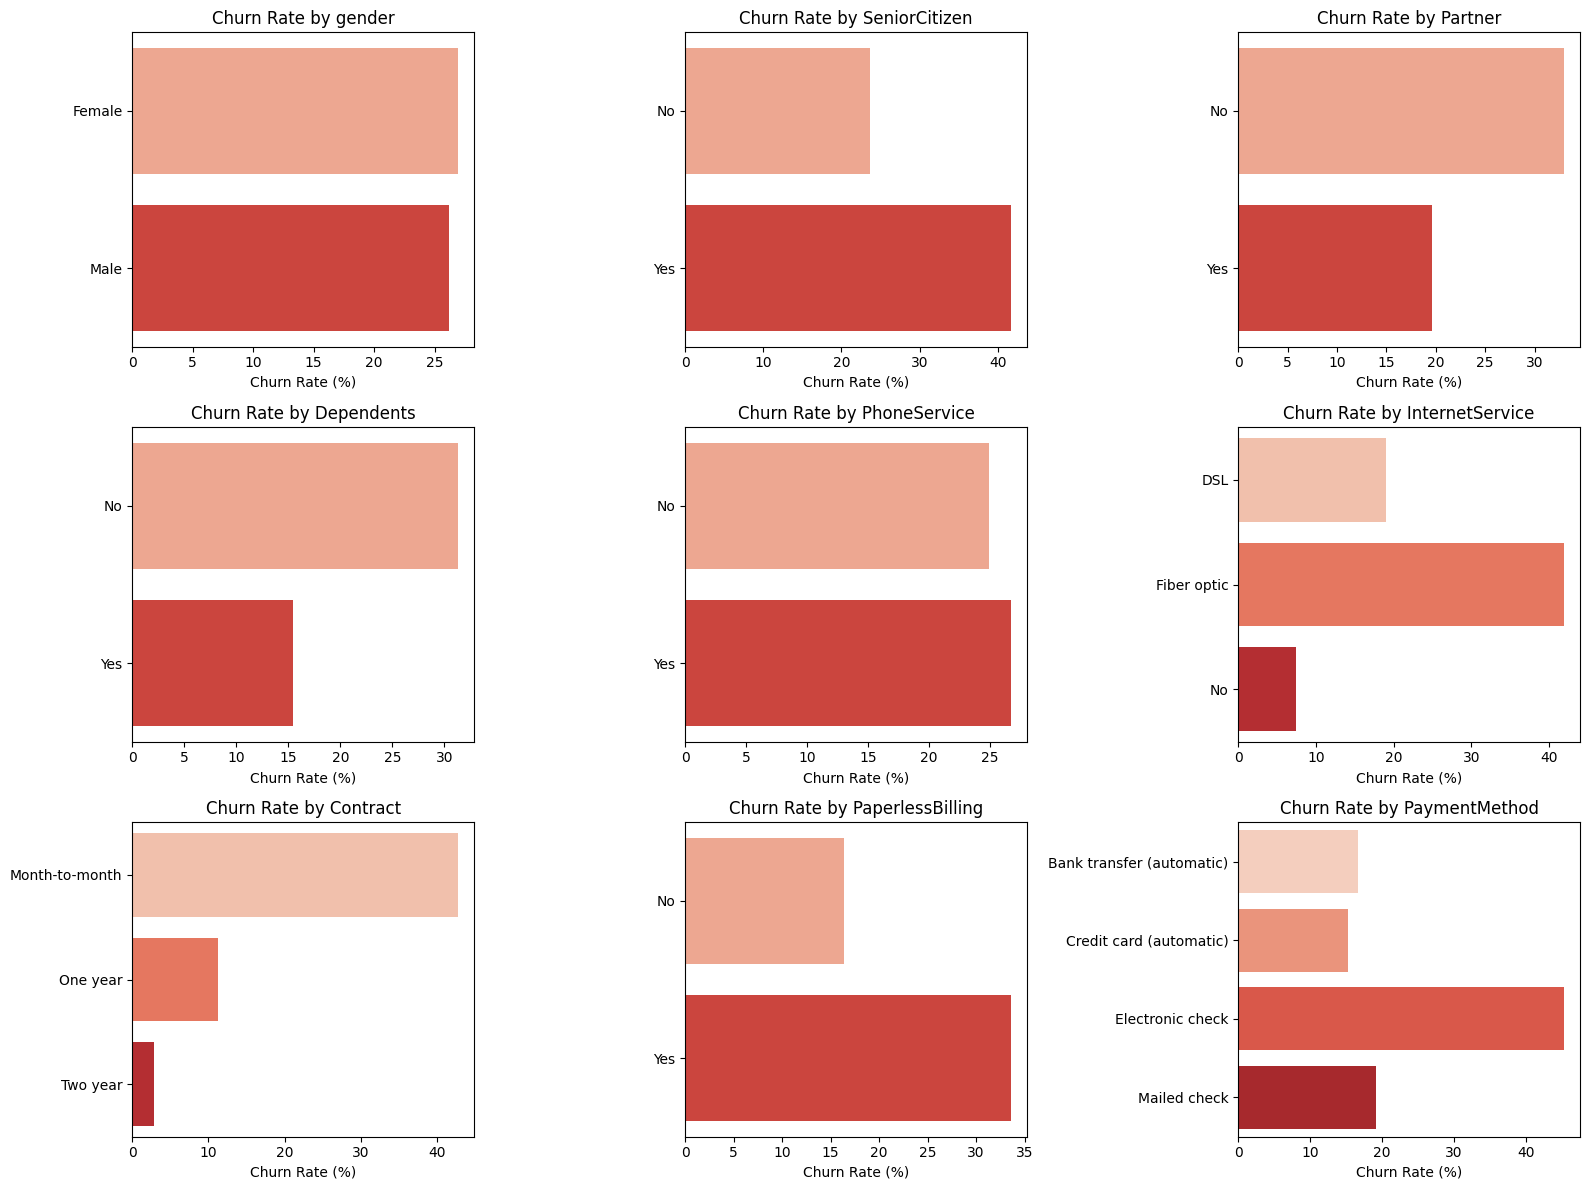

In [19]:
# Fix SeniorCitizen: replace 0/1 with No/Yes for readability
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# Churn rate per categorical column
categorical_cols = ["gender", "SeniorCitizen", "Partner", "Dependents",
                    "PhoneService", "InternetService", "Contract",
                    "PaperlessBilling", "PaymentMethod"]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    churn_rate = df.groupby(col)["Churn"].apply(
        lambda x: (x == "Yes").mean() * 100
    ).reset_index()
    churn_rate.columns = [col, "Churn Rate (%)"]
    
    sns.barplot(data=churn_rate, y=col, x="Churn Rate (%)",
                hue=col, palette="Reds", legend=False, ax=axes[i])
    axes[i].set_title(f"Churn Rate by {col}")
    axes[i].set_xlabel("Churn Rate (%)")
    axes[i].set_ylabel("")

plt.tight_layout()
plt.show()

Key findings from categorical features:

- `gender` and `PhoneService` show no meaningful difference in churn rate
  and will be dropped.
- `Contract` is the strongest predictor: Month-to-month customers churn at
  43% vs 3% for Two year contracts.
- `InternetService`: Fiber optic customers churn at 42%, DSL at 19%, and
  customers with no internet at just 7%.
- `PaymentMethod`: Electronic check customers churn at 45%, nearly 3x higher
  than other payment methods (15-20%).
- `SeniorCitizen`, `Partner`, `Dependents` and `PaperlessBilling` show
  statistically significant but weaker effects.

### Statistical Testing
Visual analysis shows patterns, but we need to confirm they are not due to 
chance. For each feature we run a statistical test and measure the effect size:
- **Chi-square + Cramér's V** for categorical features vs Churn.
- **Mann-Whitney U + r** for numeric features vs Churn.
- **Spearman** for correlations between numeric features (to confirm multicollinearity).

For all tests we use a significance threshold of p < 0.05.
A small p-value alone is not enough - with 7,043 rows almost anything becomes
significant. We also look at the effect size to assess practical importance.

In [20]:
# A. Categorical features vs Churn
# Chi-square + Cramér's V 

# H0: the categorical feature and Churn are independent
# H1: the categorical feature and Churn are not independent
# Significance threshold: p < 0.05
# Effect size: Cramér's V (small < 0.3, medium 0.3-0.5, large > 0.5)

categorical_cols = ["gender", "SeniorCitizen", "Partner", "Dependents",
                    "PhoneService", "InternetService", "Contract",
                    "PaperlessBilling", "PaymentMethod"]

print("CATEGORICAL FEATURES vs Churn")
print("-" * 55)
print(f"{'Feature':<25} {'p-value':>10} {'Cramér V':>10} {'Effect':>10}")
print("-" * 55)

for col in categorical_cols:
    contingency = pd.crosstab(df[col], df["Churn"])
    chi2, p, dof, _ = stats.chi2_contingency(contingency)
    n = contingency.sum().sum()
    cramers_v = np.sqrt(chi2 / (n * (min(contingency.shape) - 1)))
    
    if cramers_v >= 0.5:
        effect = "large"
    elif cramers_v >= 0.3:
        effect = "medium"
    else:
        effect = "small"
    
    print(f"{col:<25} {p:>10.4f} {cramers_v:>10.3f} {effect:>10}")

CATEGORICAL FEATURES vs Churn
-------------------------------------------------------
Feature                      p-value   Cramér V     Effect
-------------------------------------------------------
gender                        0.4866      0.008      small
SeniorCitizen                 0.0000      0.150      small
Partner                       0.0000      0.150      small
Dependents                    0.0000      0.164      small
PhoneService                  0.3388      0.011      small
InternetService               0.0000      0.322     medium
Contract                      0.0000      0.410     medium
PaperlessBilling              0.0000      0.191      small
PaymentMethod                 0.0000      0.303     medium


Chi-square confirms that `gender` and `PhoneService` have no statistically
significant relationship with Churn (p > 0.05) and will be dropped.
`InternetService`, `Contract` and `PaymentMethod` show medium effect sizes
(Cramér's V > 0.3), confirming them as the strongest categorical predictors.
Remaining significant features are kept - the model will determine their
combined contribution during training.

In [21]:
# B. Numeric features vs Churn
# Mann-Whitney U test for numeric features vs Churn

# H0: the distribution of the feature is the same for churners and non-churners
# H1: the distribution differs between churners and non-churners
# Significance threshold: p < 0.05
# Effect size: r = Z / sqrt(N) (small < 0.3, medium 0.3-0.5, large > 0.5)

numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

churn_yes = df[df["Churn"] == "Yes"]
churn_no = df[df["Churn"] == "No"]

print(f"{'Feature':<25} {'p-value':>10} {'r':>10} {'Effect':>10}")
print("-" * 55)

for col in numeric_cols:
    stat, p = stats.mannwhitneyu(churn_yes[col], churn_no[col], 
                                  alternative="two-sided")
    n = len(df)
    z = (stat - (len(churn_yes) * len(churn_no) / 2)) / np.sqrt(
        len(churn_yes) * len(churn_no) * (n + 1) / 12)
    r = abs(z) / np.sqrt(n)
    
    if r >= 0.5:
        effect = "large"
    elif r >= 0.3:
        effect = "medium"
    else:
        effect = "small"
    
    print(f"{col:<25} {p:>10.4f} {r:>10.3f} {effect:>10}")

Feature                      p-value          r     Effect
-------------------------------------------------------
tenure                        0.0000      0.367     medium
MonthlyCharges                0.0000      0.185      small
TotalCharges                  0.0000      0.230      small


Mann-Whitney U confirms all three numeric features have a statistically
significant relationship with Churn. `tenure` shows the strongest effect
(r = 0.367, medium), consistent with the EDA finding that newer customers
churn more. `MonthlyCharges` and `TotalCharges` show smaller but significant
effects (r = 0.185 and r = 0.230). `TotalCharges` will be dropped in feature
engineering due to multicollinearity.

Spearman correlation between numeric features

                tenure  MonthlyCharges  TotalCharges
tenure           1.000           0.276         0.890
MonthlyCharges   0.276           1.000         0.638
TotalCharges     0.890           0.638         1.000



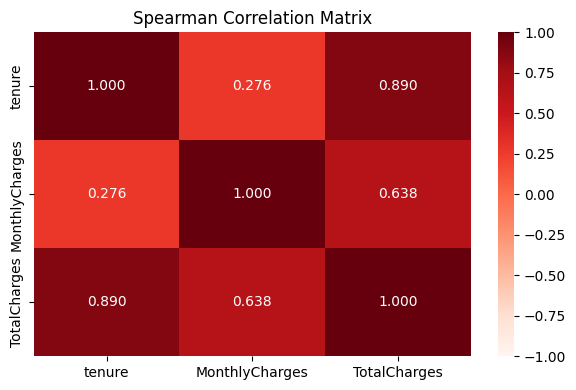

In [22]:
# Spearman correlation between numeric features

# Used to confirm multicollinearity suspicion from the EDA
# Spearman is chosen over Pearson because the distributions are skewed

numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

print("Spearman correlation between numeric features")
print()

corr_matrix = df[numeric_cols].corr(method="spearman")
print(corr_matrix.round(3))

print()

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap="Reds", 
            ax=ax, vmin=-1, vmax=1)
ax.set_title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

Spearman correlation confirms strong multicollinearity: `tenure` and
`TotalCharges` correlate at r = 0.890. `tenure` and `MonthlyCharges` are
largely independent (r = 0.276), so both are retained. `TotalCharges` is
dropped in the next step.

## 3. Feature Engineering

Based on the EDA findings, we now prepare the data for modelling:
- Drop `TotalCharges` due to multicollinearity with `tenure` and `MonthlyCharges`.
- Drop `gender` and `PhoneService` as they showed no significant relationship 
  with Churn (p > 0.05).
- Encode categorical variables into numeric format for the model.
- Create a tenure group feature to capture the non-linear relationship 
  between tenure and Churn observed in the EDA.
- Split the data into train and test sets (stratified by Churn).

In [23]:
# Drop columns with no predictive value or multicollinearity
df = df.drop(columns=["TotalCharges", "gender", "PhoneService"])
print(f"Remaining columns: {df.shape[1]}")
print(df.columns.tolist())

Remaining columns: 17
['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'Churn']


In [24]:
# Binary encoding: Yes/No --> 1/0
binary_cols = ["SeniorCitizen", "Partner", "Dependents", 
               "PaperlessBilling", "Churn"]
df[binary_cols] = df[binary_cols].apply(lambda x: x.map({"Yes": 1, "No": 0}))


# Ordinal encoding: Contract has a natural order
df["Contract"] = df["Contract"].map({"Month-to-month": 0, 
                                      "One year": 1, 
                                      "Two year": 2})


# One-Hot Encoding for nominal categorical columns
nominal_cols = ["MultipleLines", "InternetService", "OnlineSecurity", 
                "OnlineBackup", "DeviceProtection", "TechSupport", 
                "StreamingTV", "StreamingMovies", "PaymentMethod"]
df = pd.get_dummies(df, columns=nominal_cols, drop_first=True)

# Convert bool columns to int
bool_cols = df.select_dtypes(include="bool").columns
df[bool_cols] = df[bool_cols].astype(int)

print(f"Shape after encoding: {df.shape}")
print(df.dtypes)

Shape after encoding: (7043, 27)
SeniorCitizen                              int64
Partner                                    int64
Dependents                                 int64
tenure                                     int64
Contract                                   int64
PaperlessBilling                           int64
MonthlyCharges                           float64
Churn                                      int64
MultipleLines_No phone service             int64
MultipleLines_Yes                          int64
InternetService_Fiber optic                int64
InternetService_No                         int64
OnlineSecurity_No internet service         int64
OnlineSecurity_Yes                         int64
OnlineBackup_No internet service           int64
OnlineBackup_Yes                           int64
DeviceProtection_No internet service       int64
DeviceProtection_Yes                       int64
TechSupport_No internet service            int64
TechSupport_Yes                     

tenure_group
0-6m      52.9
6-12m     35.9
12-24m    28.7
24-48m    20.4
48-72m     9.5
Name: Churn, dtype: float64


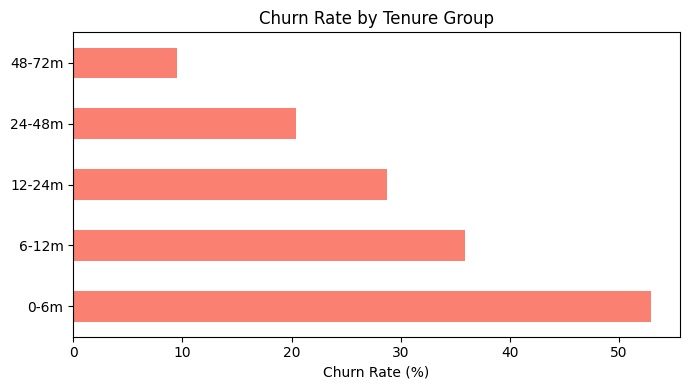

In [25]:
# Tenure group: churn rate analysis and feature creation
bins = [0, 6, 12, 24, 48, 72]
labels = ["0-6m", "6-12m", "12-24m", "24-48m", "48-72m"]

df["tenure_group"] = pd.cut(df["tenure"], bins=bins, labels=labels,
                             include_lowest=True)

# Show churn rate per group to justify the boundaries
churn_by_tenure = df.groupby("tenure_group", observed=True)["Churn"].mean() * 100
print(churn_by_tenure.round(1))

fig, ax = plt.subplots(figsize=(7, 4))
churn_by_tenure.plot(kind="barh", ax=ax, color="salmon")
ax.set_title("Churn Rate by Tenure Group")
ax.set_xlabel("Churn Rate (%)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

# Encode as ordinal (natural order: shorter tenure = higher churn risk)
tenure_order = {"0-6m": 0, "6-12m": 1, "12-24m": 2, "24-48m": 3, "48-72m": 4}
df["tenure_group"] = df["tenure_group"].map(tenure_order).astype(int)

In [26]:
print(df[["tenure", "tenure_group"]].head(10))
print(f"\nShape: {df.shape}")

   tenure  tenure_group
0       1             0
1      34             3
2       2             0
3      45             3
4       2             0
5       8             1
6      22             2
7      10             1
8      28             3
9      62             4

Shape: (7043, 28)


In [27]:
# Check how many services each customer has
service_cols = ["OnlineSecurity_Yes", "OnlineBackup_Yes", 
                "DeviceProtection_Yes", "TechSupport_Yes", 
                "StreamingTV_Yes", "StreamingMovies_Yes"]

df["num_services"] = df[service_cols].sum(axis=1)

print(df["num_services"].value_counts().sort_index())
print()

# Churn rate per number of services
churn_by_services = df.groupby("num_services")["Churn"].mean() * 100
print("Churn rate by number of services:")
print(churn_by_services.round(1))

num_services
0    2219
1     966
2    1033
3    1118
4     852
5     571
6     284
Name: count, dtype: int64

Churn rate by number of services:
num_services
0    21.4
1    45.8
2    35.8
3    27.4
4    22.3
5    12.4
6     5.3
Name: Churn, dtype: float64


In [28]:
# Check if customers with 0 services have no internet
print(df[df["num_services"] == 0]["InternetService_No"].value_counts())

InternetService_No
1    1526
0     693
Name: count, dtype: int64


In [29]:
# Churn rate for customers with 0 services split by internet service
mask_0_services = df["num_services"] == 0
print(df[mask_0_services].groupby("InternetService_No")["Churn"].mean() * 100)

InternetService_No
0    52.236652
1     7.404980
Name: Churn, dtype: float64


In [30]:
# Create num_services feature: total number of extra services per customer
service_cols = ["OnlineSecurity_Yes", "OnlineBackup_Yes", 
                "DeviceProtection_Yes", "TechSupport_Yes", 
                "StreamingTV_Yes", "StreamingMovies_Yes"]

df["num_services"] = df[service_cols].sum(axis=1)

In [31]:
print(f"Shape after encoding: {df.shape}")
print(df.dtypes)

Shape after encoding: (7043, 29)
SeniorCitizen                              int64
Partner                                    int64
Dependents                                 int64
tenure                                     int64
Contract                                   int64
PaperlessBilling                           int64
MonthlyCharges                           float64
Churn                                      int64
MultipleLines_No phone service             int64
MultipleLines_Yes                          int64
InternetService_Fiber optic                int64
InternetService_No                         int64
OnlineSecurity_No internet service         int64
OnlineSecurity_Yes                         int64
OnlineBackup_No internet service           int64
OnlineBackup_Yes                           int64
DeviceProtection_No internet service       int64
DeviceProtection_Yes                       int64
TechSupport_No internet service            int64
TechSupport_Yes                     

A `num_services` feature was engineered by summing the 6 binary service columns.
Churn rate peaks at 1-2 services (46% and 36%) and drops steadily to 5.3% at
6 services, suggesting that customers with more services are more "locked in".
The 0-service group is misleading as an average: customers without internet
churn at just 7.4%, while those with internet but no extra services churn at
52.2%. The engineered feature captures this non-linear relationship.

In [32]:
# Train/Test split

# Separate features and target
X = df.drop(columns=["Churn"])
y = df["Churn"]

# Stratified split to maintain class balance (73.5% No / 26.5% Yes)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print()
print(f"Churn rate in train: {y_train.mean() * 100:.1f}%")
print(f"Churn rate in test:  {y_test.mean() * 100:.1f}%")

X_train shape: (5634, 28)
X_test shape:  (1409, 28)

Churn rate in train: 26.5%
Churn rate in test:  26.5%


Data split into 80% train (5,634 rows) and 20% test (1,409 rows) using
stratified sampling to preserve the 73.5/26.5 class balance in both sets.

## 4. Modelling

We train and compare 4 models:
1. Logistic Regression (baseline)
2. Decision Tree
3. Random Forest
4. XGBoost

### Approach
1. Compare 3 imbalance-handling techniques using Logistic Regression 
   and 5-fold cross-validation (F1 score):
   - No handling (baseline)
   - class_weight="balanced"
   - SMOTE
2. Apply the best technique to all 4 models.
3. Tune hyperparameters with Optuna for each model.
4. Final evaluation on the test set (once, at the end).

### Evaluation metrics
- **F1:** main metric, balances precision and recall.
- **Precision:** how many predicted churners actually churned.
- **Recall:** how many actual churners were identified.
- **ROC-AUC:** overall model performance across all thresholds.

In [33]:
# Baseline - no imbalance handling
lr = LogisticRegression(random_state=SEED, max_iter=1000)
scores_baseline = cross_val_score(lr, X_train, y_train, 
                                   cv=5, scoring="f1")

# class_weight="balanced"
lr_balanced = LogisticRegression(random_state=SEED, max_iter=1000,
                                  class_weight="balanced")
scores_balanced = cross_val_score(lr_balanced, X_train, y_train, 
                                   cv=5, scoring="f1")

# SMOTE inside pipeline to avoid data leakage
smote_pipeline = ImbPipeline([
    ("smote", SMOTE(random_state=SEED)),
    ("lr", LogisticRegression(random_state=SEED, max_iter=1000))
])
scores_smote = cross_val_score(smote_pipeline, X_train, y_train, 
                                cv=5, scoring="f1")

print("Imbalance handling comparison (Logistic Regression, 5-fold CV, F1)")
print(" ")
print(f"Baseline:          {scores_baseline.mean():.3f} (+/- {scores_baseline.std():.3f})")
print(f"class_weight:      {scores_balanced.mean():.3f} (+/- {scores_balanced.std():.3f})")
print(f"SMOTE:             {scores_smote.mean():.3f} (+/- {scores_smote.std():.3f})")


Imbalance handling comparison (Logistic Regression, 5-fold CV, F1)
 
Baseline:          0.591 (+/- 0.025)
class_weight:      0.633 (+/- 0.027)
SMOTE:             0.610 (+/- 0.020)


Three imbalance-handling techniques were compared using Logistic Regression
and 5-fold cross-validation. `class_weight="balanced"` achieved the best
F1 (0.633) and was selected for all models. SMOTE was discarded after
correcting a data leakage issue (F1 dropped from 0.797 to 0.610 once SMOTE
was applied inside the CV pipeline rather than before it).

### Hyperparameter Tuning with Optuna

In [34]:
# Early stopping callback
def early_stopping(study, trial, patience=15):
    if trial.number >= patience:
        best_trial = study.best_trial
        if trial.number - best_trial.number >= patience:
            study.stop()

optuna.logging.set_verbosity(optuna.logging.WARNING)

In [35]:
# LogisticRegression
def objective_lr(trial):
    C = trial.suggest_float("C", 0.01, 10.0, log=True)
    solver = trial.suggest_categorical("solver", ["lbfgs", "saga"])
    
    model = LogisticRegression(C=C, solver=solver, 
                                class_weight="balanced",
                                random_state=SEED, max_iter=5000)
    scores = cross_val_score(model, X_train, y_train,
                             cv=5, scoring="f1")
    
    print(f"Trial {trial.number}: F1 = {scores.mean():.4f} | C = {C:.4f}, solver = {solver}")
    return scores.mean()

study_lr = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=SEED))
study_lr.optimize(objective_lr, n_trials=50,
                  callbacks=[early_stopping])

print("Logistic Regression - Best params:")
print(study_lr.best_params)
print(f"Best F1: {study_lr.best_value:.3f}")

Trial 0: F1 = 0.6330 | C = 0.1329, solver = lbfgs
Trial 1: F1 = 0.6347 | C = 0.6251, solver = lbfgs
Trial 2: F1 = 0.6313 | C = 0.0149, solver = lbfgs
Trial 3: F1 = 0.6359 | C = 1.3311, solver = saga
Trial 4: F1 = 0.6321 | C = 3.1429, solver = lbfgs
Trial 5: F1 = 0.6314 | C = 0.0355, solver = saga
Trial 6: F1 = 0.6345 | C = 0.1976, solver = saga
Trial 7: F1 = 0.6301 | C = 0.0262, solver = saga
Trial 8: F1 = 0.6351 | C = 0.2335, solver = lbfgs
Trial 9: F1 = 0.6343 | C = 0.3489, solver = lbfgs
Trial 10: F1 = 0.6356 | C = 9.1629, solver = saga
Trial 11: F1 = 0.6356 | C = 8.1024, solver = saga
Trial 12: F1 = 0.6359 | C = 0.9392, solver = saga
Trial 13: F1 = 0.6359 | C = 0.7925, solver = saga
Trial 14: F1 = 0.6359 | C = 0.9302, solver = saga
Trial 15: F1 = 0.6356 | C = 1.9858, solver = saga
Trial 16: F1 = 0.6356 | C = 0.4119, solver = saga
Trial 17: F1 = 0.6356 | C = 2.1240, solver = saga
Trial 18: F1 = 0.6335 | C = 1.6113, solver = lbfgs
Trial 19: F1 = 0.6327 | C = 0.0880, solver = saga
Tri

In [36]:
# DecisionTree
def objective_dt(trial):
    max_depth = trial.suggest_int("max_depth", 2, 20)
    min_samples_split = trial.suggest_int("min_samples_split", 2, 50)
    min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 20)
    
    model = DecisionTreeClassifier(
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        class_weight="balanced",
        random_state=SEED
    )
    scores = cross_val_score(model, X_train, y_train,
                             cv=5, scoring="f1")
    
    print(f"Trial {trial.number}: F1 = {scores.mean():.4f} | max_depth = {max_depth}, min_samples_split = {min_samples_split}, min_samples_leaf = {min_samples_leaf}")
    return scores.mean()

study_dt = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=SEED))
study_dt.optimize(objective_dt, n_trials=50,
                  callbacks=[early_stopping])

print("Decision Tree - Best params:")
print(study_dt.best_params)
print(f"Best F1: {study_dt.best_value:.3f}")

Trial 0: F1 = 0.5973 | max_depth = 9, min_samples_split = 48, min_samples_leaf = 15
Trial 1: F1 = 0.5518 | max_depth = 13, min_samples_split = 9, min_samples_leaf = 4
Trial 2: F1 = 0.6204 | max_depth = 3, min_samples_split = 44, min_samples_leaf = 13
Trial 3: F1 = 0.6033 | max_depth = 15, min_samples_split = 3, min_samples_leaf = 20
Trial 4: F1 = 0.5485 | max_depth = 17, min_samples_split = 12, min_samples_leaf = 4
Trial 5: F1 = 0.6174 | max_depth = 5, min_samples_split = 16, min_samples_leaf = 11
Trial 6: F1 = 0.5909 | max_depth = 10, min_samples_split = 16, min_samples_leaf = 13
Trial 7: F1 = 0.6084 | max_depth = 4, min_samples_split = 16, min_samples_leaf = 8
Trial 8: F1 = 0.5875 | max_depth = 10, min_samples_split = 40, min_samples_leaf = 4
Trial 9: F1 = 0.5739 | max_depth = 11, min_samples_split = 31, min_samples_leaf = 1
Trial 10: F1 = 0.6204 | max_depth = 3, min_samples_split = 43, min_samples_leaf = 2
Trial 11: F1 = 0.6204 | max_depth = 3, min_samples_split = 40, min_samples_le

In [37]:
# RandomForest
def objective_rf(trial):
    n_estimators = trial.suggest_int("n_estimators", 50, 500)
    max_depth = trial.suggest_int("max_depth", 2, 20)
    min_samples_split = trial.suggest_int("min_samples_split", 2, 50)
    min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 20)
    max_features = trial.suggest_categorical("max_features", ["sqrt", "log2"])
    
    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    )
    scores = cross_val_score(model, X_train, y_train,
                             cv=5, scoring="f1")
    
    print(f"Trial {trial.number}: F1 = {scores.mean():.4f} | n_estimators = {n_estimators}, max_depth = {max_depth}, max_features = {max_features}")
    return scores.mean()

study_rf = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=SEED))
study_rf.optimize(objective_rf, n_trials=100,
                  callbacks=[early_stopping])

print("Random Forest - Best params:")
print(study_rf.best_params)
print(f"Best F1: {study_rf.best_value:.3f}")

Trial 0: F1 = 0.6385 | n_estimators = 218, max_depth = 20, max_features = sqrt
Trial 1: F1 = 0.6325 | n_estimators = 76, max_depth = 18, max_features = log2
Trial 2: F1 = 0.6313 | n_estimators = 425, max_depth = 6, max_features = log2
Trial 3: F1 = 0.6336 | n_estimators = 244, max_depth = 7, max_features = log2
Trial 4: F1 = 0.6361 | n_estimators = 255, max_depth = 16, max_features = sqrt
Trial 5: F1 = 0.6272 | n_estimators = 324, max_depth = 5, max_features = sqrt
Trial 6: F1 = 0.6196 | n_estimators = 187, max_depth = 3, max_features = log2
Trial 7: F1 = 0.6351 | n_estimators = 65, max_depth = 19, max_features = log2
Trial 8: F1 = 0.6280 | n_estimators = 296, max_depth = 5, max_features = sqrt
Trial 9: F1 = 0.6350 | n_estimators = 319, max_depth = 19, max_features = log2
Trial 10: F1 = 0.6332 | n_estimators = 258, max_depth = 17, max_features = sqrt
Trial 11: F1 = 0.6342 | n_estimators = 190, max_depth = 19, max_features = sqrt
Trial 12: F1 = 0.6376 | n_estimators = 344, max_depth = 1

In [38]:
# xgboost

# Calculate scale_pos_weight for class imbalance = number of negative cases / number of positive cases
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight: {scale_pos_weight:.2f}")

def objective_xgb(trial):
    n_estimators = trial.suggest_int("n_estimators", 50, 500)
    max_depth = trial.suggest_int("max_depth", 2, 10)
    learning_rate = trial.suggest_float("learning_rate", 0.01, 0.3, log=True)
    subsample = trial.suggest_float("subsample", 0.5, 1.0)
    colsample_bytree = trial.suggest_float("colsample_bytree", 0.5, 1.0)
    
    model = XGBClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        learning_rate=learning_rate,
        subsample=subsample,
        colsample_bytree=colsample_bytree,
        scale_pos_weight=scale_pos_weight,
        random_state=SEED,
        eval_metric="logloss",
        verbosity=0
    )
    scores = cross_val_score(model, X_train, y_train,
                             cv=5, scoring="f1")
    
    print(f"Trial {trial.number}: F1 = {scores.mean():.4f} | n_estimators = {n_estimators}, max_depth = {max_depth}, learning_rate = {learning_rate:.4f}")
    return scores.mean()

study_xgb = optuna.create_study(direction="maximize",
                                 sampler=optuna.samplers.TPESampler(seed=SEED))
study_xgb.optimize(objective_xgb, n_trials=100,
                   callbacks=[early_stopping])

print("XGBoost - Best params:")
print(study_xgb.best_params)
print(f"Best F1: {study_xgb.best_value:.3f}")

scale_pos_weight: 2.77
Trial 0: F1 = 0.5819 | n_estimators = 218, max_depth = 10, learning_rate = 0.1206
Trial 1: F1 = 0.6352 | n_estimators = 120, max_depth = 2, learning_rate = 0.1903
Trial 2: F1 = 0.5984 | n_estimators = 59, max_depth = 10, learning_rate = 0.1697
Trial 3: F1 = 0.6365 | n_estimators = 132, max_depth = 4, learning_rate = 0.0596
Trial 4: F1 = 0.6348 | n_estimators = 325, max_depth = 3, learning_rate = 0.0270
Trial 5: F1 = 0.6301 | n_estimators = 404, max_depth = 3, learning_rate = 0.0575
Trial 6: F1 = 0.6317 | n_estimators = 324, max_depth = 3, learning_rate = 0.0125
Trial 7: F1 = 0.6323 | n_estimators = 414, max_depth = 4, learning_rate = 0.0139
Trial 8: F1 = 0.6331 | n_estimators = 105, max_depth = 6, learning_rate = 0.0112
Trial 9: F1 = 0.6314 | n_estimators = 348, max_depth = 4, learning_rate = 0.0586
Trial 10: F1 = 0.6290 | n_estimators = 81, max_depth = 4, learning_rate = 0.0282
Trial 11: F1 = 0.6312 | n_estimators = 185, max_depth = 2, learning_rate = 0.1538
Tri

Hyperparameters were tuned with Optuna (50-100 trials, early stopping at
patience=15) using 5-fold cross-validation. All models converge to similar
CV F1 scores (0.620-0.638), suggesting that feature quality matters more
than algorithm choice for this problem. Notable finding: Decision Tree
consistently peaks at max_depth=3 - deeper trees overfit, while Random
Forest tolerates deeper trees through bagging and random feature selection.

### Final models

Each model is trained on the full X_train with the best hyperparameters found by Optuna.

In [39]:
# Train each model with best params on full X_train
models = {
    "Logistic Regression": LogisticRegression(
        C=study_lr.best_params["C"],
        solver=study_lr.best_params["solver"],
        class_weight="balanced",
        random_state=SEED,
        max_iter=5000
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=study_dt.best_params["max_depth"],
        min_samples_split=study_dt.best_params["min_samples_split"],
        min_samples_leaf=study_dt.best_params["min_samples_leaf"],
        class_weight="balanced",
        random_state=SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=study_rf.best_params["n_estimators"],
        max_depth=study_rf.best_params["max_depth"],
        min_samples_split=study_rf.best_params["min_samples_split"],
        min_samples_leaf=study_rf.best_params["min_samples_leaf"],
        max_features=study_rf.best_params["max_features"],
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=study_xgb.best_params["n_estimators"],
        max_depth=study_xgb.best_params["max_depth"],
        learning_rate=study_xgb.best_params["learning_rate"],
        subsample=study_xgb.best_params["subsample"],
        colsample_bytree=study_xgb.best_params["colsample_bytree"],
        scale_pos_weight=scale_pos_weight,
        random_state=SEED,
        eval_metric="logloss",
        verbosity=0
    )
}


### Final Evaluation on the Test Set
We now evaluate all 4 models on the test set (used for the first and only time).

In [40]:
# Train each model with best params on full X_train, evaluate on X_test
models = {
    "Logistic Regression": LogisticRegression(
        C=study_lr.best_params["C"],
        solver=study_lr.best_params["solver"],
        class_weight="balanced",
        random_state=SEED,
        max_iter=5000
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=study_dt.best_params["max_depth"],
        min_samples_split=study_dt.best_params["min_samples_split"],
        min_samples_leaf=study_dt.best_params["min_samples_leaf"],
        class_weight="balanced",
        random_state=SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=study_rf.best_params["n_estimators"],
        max_depth=study_rf.best_params["max_depth"],
        min_samples_split=study_rf.best_params["min_samples_split"],
        min_samples_leaf=study_rf.best_params["min_samples_leaf"],
        max_features=study_rf.best_params["max_features"],
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=study_xgb.best_params["n_estimators"],
        max_depth=study_xgb.best_params["max_depth"],
        learning_rate=study_xgb.best_params["learning_rate"],
        subsample=study_xgb.best_params["subsample"],
        colsample_bytree=study_xgb.best_params["colsample_bytree"],
        scale_pos_weight=scale_pos_weight,
        random_state=SEED,
        eval_metric="logloss",
        verbosity=0
    )
}

# Evaluate all models
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    results[name] = {
        "F1":        f1_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "ROC-AUC":   roc_auc_score(y_test, y_prob)
    }

# Print results table
print(f"{'Model':<25} {'F1':>8} {'Precision':>10} {'Recall':>8} {'ROC-AUC':>10}")
print("-" * 65)
for name, metrics in results.items():
    print(f"{name:<25} {metrics['F1']:>8.3f} {metrics['Precision']:>10.3f} {metrics['Recall']:>8.3f} {metrics['ROC-AUC']:>10.3f}")

Model                           F1  Precision   Recall    ROC-AUC
-----------------------------------------------------------------
Logistic Regression          0.622      0.514    0.786      0.842
Decision Tree                0.621      0.514    0.783      0.816
Random Forest                0.640      0.542    0.783      0.844
XGBoost                      0.633      0.523    0.802      0.843


All models perform similarly on the test set (F1: 0.621-0.640, ROC-AUC:
0.816-0.844). XGBoost is selected as the final model based on Recall (0.802),
the most business-relevant metric: missing a churner costs more than sending
an unnecessary retention offer. Logistic Regression performs close to the more
complex models, further confirming that feature engineering drove most of the
predictive signal.

## 5. Interpretation

We now look inside the best model (XGBoost) to understand which features
drive its predictions. This answers the last two questions from the intro:
- **Can we predict it?** Yes - XGBoost achieves Recall = 0.802 and ROC-AUC = 0.843.
- **What should the company do?** Based on feature importance and SHAP values.

We use two approaches:
- **Feature importance:** which features the model relies on most globally.
- **SHAP:** how each feature affects each individual prediction.

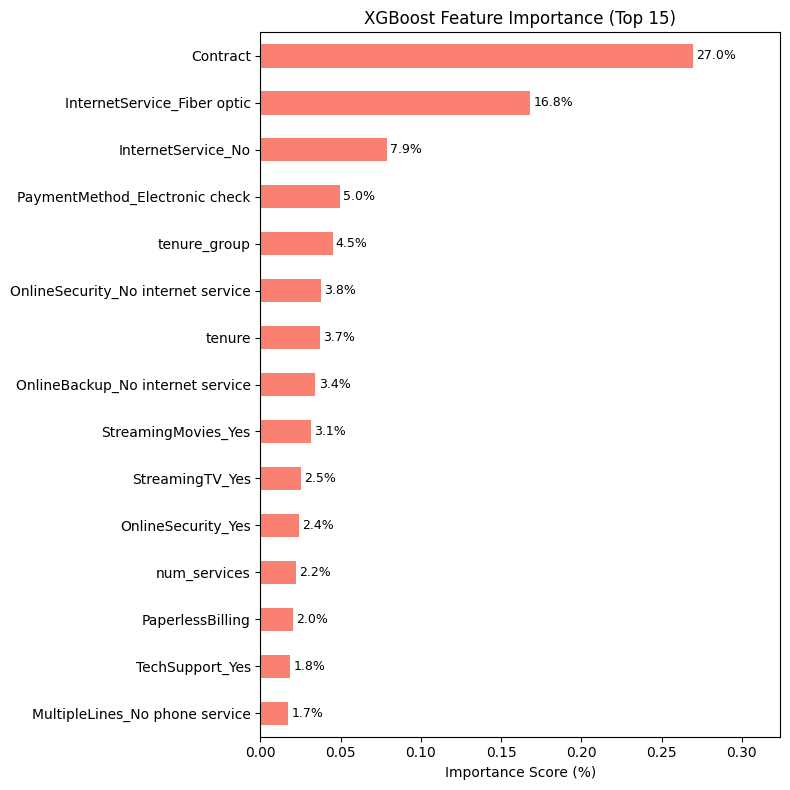

In [41]:
# Feature importance from XGBoost
best_xgb_model = models["XGBoost"]

fig, ax = plt.subplots(figsize=(8, 8))
importance = pd.Series(best_xgb_model.feature_importances_, 
                        index=X_train.columns).sort_values(ascending=True)
top15 = importance.tail(15)
top15.plot(kind="barh", ax=ax, color="salmon")

# Add value labels as percentages
for i, (val, name) in enumerate(zip(top15.values, top15.index)):
    ax.text(val + 0.002, i, f"{val*100:.1f}%", va="center", fontsize=9)

ax.set_title("XGBoost Feature Importance (Top 15)")
ax.set_xlabel("Importance Score (%)")
ax.set_xlim(0, top15.max() * 1.2)
plt.tight_layout()
plt.show()

`Contract` is the dominant predictor (27.0%), followed by `InternetService_Fiber optic`
(16.8%) and `InternetService_No` (7.9%). Both engineered features (`tenure_group`
and `num_services`) appear in the top 15, validating the feature engineering
decisions. SHAP values below provide directional insight into each feature's effect.

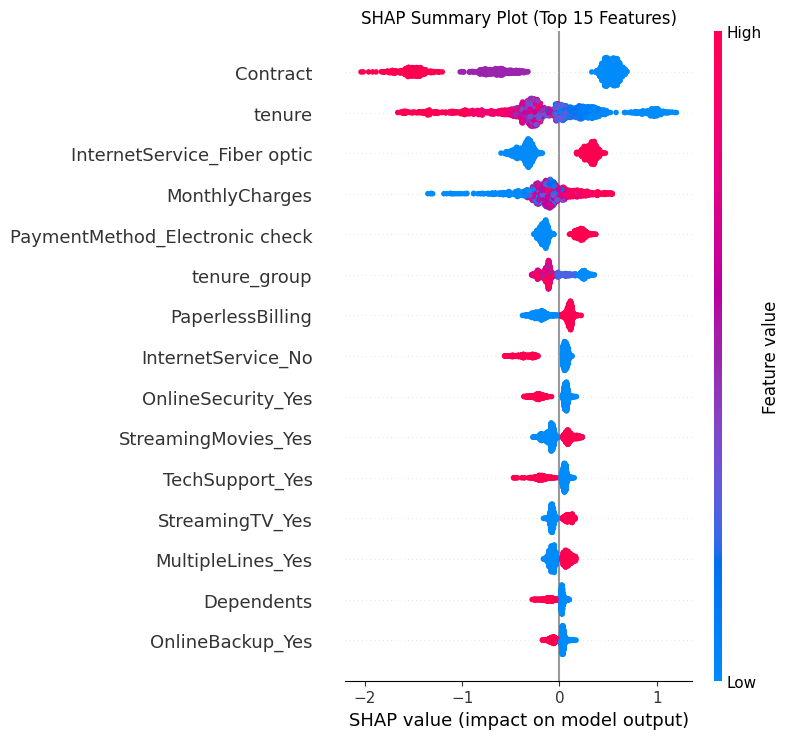

In [42]:
import warnings
warnings.filterwarnings("ignore")

# SHAP values for XGBoost
explainer = shap.TreeExplainer(best_xgb_model)
shap_values = explainer.shap_values(X_test)

# Summary plot - shows feature importance and direction of effect
shap.summary_plot(shap_values, X_test, max_display=15, show=False)
plt.title("SHAP Summary Plot (Top 15 Features)")
plt.tight_layout()
plt.show()

SHAP confirms the directionality of each feature's effect: Month-to-month
contracts, short tenure, Fiber optic internet, high MonthlyCharges and
Electronic check payments all increase churn probability. Two-year contracts,
long tenure and no internet service strongly decrease it. These findings
directly inform the business recommendations below.

## 6. Business Recommendations

Based on the EDA findings and XGBoost model interpretation (feature importance
and SHAP values), the following actions are recommended:

**1. Focus retention efforts on new customers (0-12 months)**
The first year is the critical period: 47.4% of new customers churn.
The company should invest in onboarding programs, proactive support and
early incentives specifically for customers in their first 12 months.

**2. Incentivize long-term contracts**
Month-to-month customers churn at 43% vs 3% for two-year contracts.
The company should offer discounts or benefits to encourage customers
to switch from month-to-month to annual or two-year contracts.

**3. Review Fiber optic pricing and quality**
Fiber optic customers churn at 42%, the highest of any internet service type.
This suggests either a pricing issue or a quality/satisfaction problem
that needs to be investigated.

**4. Upsell services to new customers**
Customers with 3+ services churn at less than 20%, while those with 1-2
services churn at 35-46%. Encouraging new customers to add services early
increases their "lock-in" and reduces churn risk.

**5. Investigate Electronic check payment method**
Customers paying by Electronic check churn at 45%, much higher than other
payment methods (15-20%). The company should investigate whether this is
correlated with a specific customer profile or a friction point in the
payment experience.

> **Note:** These recommendations are based on correlations observed in the data.
Causality cannot be confirmed without further investigation (e.g. A/B testing).

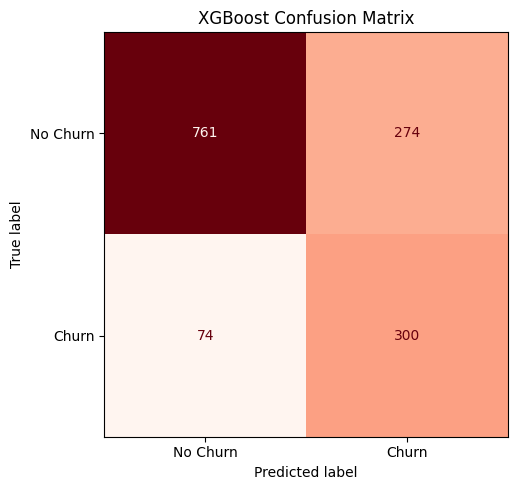

True Negatives  (correct No Churn):   761
False Positives (wrong Churn):         274
False Negatives (missed Churners):     74
True Positives  (correct Churn):       300

Of 374 actual churners, the model identified 300 (80.2%)
Of 1035 actual non-churners, 274 were wrongly flagged (26.5%)


In [43]:
# Confusion matrix for XGBoost (best model)
fig, ax = plt.subplots(figsize=(6, 5))

cm = confusion_matrix(y_test, models["XGBoost"].predict(X_test))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
                               display_labels=["No Churn", "Churn"])
disp.plot(cmap="Reds", ax=ax, colorbar=False)
ax.set_title("XGBoost Confusion Matrix")
plt.tight_layout()
plt.show()

# Print in numbers
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives  (correct No Churn):   {tn}")
print(f"False Positives (wrong Churn):         {fp}")
print(f"False Negatives (missed Churners):     {fn}")
print(f"True Positives  (correct Churn):       {tp}")
print()
print(f"Of {tp + fn} actual churners, the model identified {tp} ({tp/(tp+fn)*100:.1f}%)")
print(f"Of {tn + fp} actual non-churners, {fp} were wrongly flagged ({fp/(tn+fp)*100:.1f}%)")

The model correctly identified 300 of 374 actual churners (Recall = 80.2%).
74 churners were missed (False Negatives) and 274 non-churners were wrongly
flagged (False Positives). Given that missing a churner is more costly than
sending an unnecessary retention offer, this trade-off is acceptable.